# Duration, convexity and key rates

Research question: Which perturbation does each risk number measure?

Inputs: frozen Treasury 2024–2025 CSVs. Rates are decimals, prices per 100 face. Release 1.0.0. No live signal.

In [1]:
import sys,json
from pathlib import Path
from datetime import date
import numpy as np
R=Path.cwd()
if R.name=='notebooks':R=R.parent
sys.path.insert(0,str(R/'src'));sys.path.insert(0,str(R/'scripts'))
from curve_lab.data import load_history
from curve_lab.bonds import Bond
from curve_lab.curves import bootstrap,par_rate,TENORS,KEYS,fit_nelson_siegel
from curve_lab.risk import bond_risk,hedge,carry_bridge
from curve_lab.forecast import predict,evaluate
from review_display import table,figure
if 'display_bundle' not in globals():
    from IPython.display import display
    def display_bundle(bundle):display(bundle,raw=True)
D=json.loads((R/'artifacts/release/research.json').read_text());rows,receipts=load_history(R)
print('Run',D['run_id'],'| source through',D['as_of'],'| hypothetical bond valuations')


Run p4-662f58a64e8e | source through 2025-12-31 | hypothetical bond valuations


## Compare analytic and finite-difference yield risk

In [2]:
s=date(2025,12,31);b=Bond(date(2030,12,31),.04);c=bootstrap(rows[-1]['par']);p=b.curve_price(s,c);y=b.ytm(s,p);r=b.yield_risk(s,y);fd=(b.yield_price(s,y-1e-5)-b.yield_price(s,y+1e-5))/(2e-5*p);display_bundle(table(['Measure','Value'],list(r.items())+[['FD modified duration',fd]]));assert abs(fd-r['modified'])<1e-7

Measure,Value
macaulay,4.5841943
modified,4.5002366
convexity,23.581239
dv01,0.045549385
FD modified duration,4.5002366


## Reprice each key-rate bump

Key tenor,DV01 per 100
0.5,0.00032175261
2,0.0020350263
5,0.044026646
10,2.3225536e-05
20,0
30,0


Sum minus parallel DV01 -4.375522166810697e-11


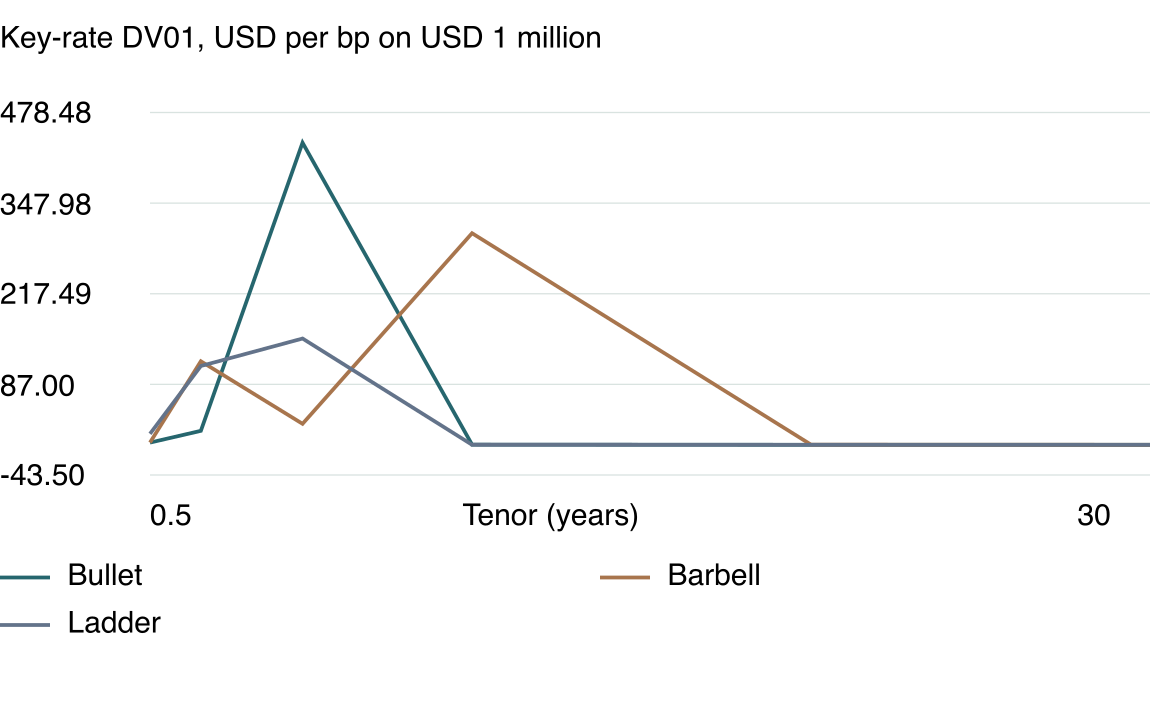

In [3]:
kr=bond_risk(b,s,c);display_bundle(table(['Key tenor','DV01 per 100'],zip(KEYS,kr['key_dv01'])));print('Sum minus parallel DV01',kr['key_sum_residual']);display_bundle(figure('keyrates'));assert abs(kr['key_sum_residual'])<1e-7

## Compare small and large shocks

In [4]:
display_bundle(table(['Shock bp','Full P&L','Duration','Duration + convexity'],[[bp,b.curve_price(s,c.bumped(np.full(6,bp/10000)))-p,-p*kr['curve_duration']*bp/10000,p*(-kr['curve_duration']*bp/10000+.5*kr['curve_convexity']*(bp/10000)**2)] for bp in [-200,-100,1,100,200]]))

Shock bp,Full P&L,Duration,Duration + convexity
-200,9.7456275,9.2813301,9.7305221
-100,4.7548276,4.6406651,4.7529631
1,-0.046395421,-0.046406651,-0.046395421
100,-4.530186,-4.6406651,-4.5283671
200,-8.8465134,-9.2813301,-8.8321381


## Interpretation

Yield and curve duration are distinct. Zero-rate hats partition unity and central finite-bump key DV01 aggregates approximately. Full repricing remains the stress reference.

Canonical evidence: `artifacts/release/research.json`; source receipts: `data/manifests/sources.json`.